# Semana 8 · Tratamiento de imagen: diagnóstico y corrección
## CADI Percepción Computacional · Experiencia IMAGEN
**Ruby Dayana Cárdenas Gómez** · Universidad de Cundinamarca · Octubre 2026

En este cuaderno analizo cinco fotos de un mismo objeto tomadas en condiciones distintas, mido sus características con OpenCV, identifico cuál es la más problemática y le aplico un tratamiento justificado, comparando antes y después con números y con imágenes.

## 0. Librerías

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)

def mostrar(imagen, titulo="", ax=None):
    # Muestra una imagen de OpenCV con los colores correctos (BGR -> RGB)
    ax = ax or plt.gca()
    if imagen.ndim == 2:
        ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    ax.set_title(titulo, fontsize=10); ax.axis("off")

OpenCV: 4.13.0


## 1. Las cinco imágenes

Subo las cinco fotos del mismo objeto. Los nombres de archivo deben ser exactamente estos (en minúscula y con extensión .jpg):

| Archivo | Condición de captura |
|---|---|
| `referencia.jpg` | Buena luz, objeto centrado, fondo sencillo |
| `baja_luz.jpg` | Poca iluminación (luz apagada o a contraluz) |
| `desenfoque.jpg` | Movimiento o foto desenfocada |
| `fondo_complejo.jpg` | El objeto sobre un fondo lleno de cosas |
| `angulo.jpg` | Otro ángulo, distancia o perspectiva |

In [2]:
from google.colab import files
print("Sube las cinco fotos (puedes seleccionarlas todas a la vez):")
cargados = files.upload()

CONDICIONES = {
    "referencia.jpg":    "Referencia (buena luz)",
    "baja_luz.jpg":      "Baja iluminación",
    "desenfoque.jpg":    "Desenfoque / movimiento",
    "fondo_complejo.jpg":"Fondo complejo",
    "angulo.jpg":        "Cambio de ángulo / distancia",
}

imagenes = {}
for archivo, condicion in list(CONDICIONES.items()):
    ruta = archivo if os.path.exists(archivo) else archivo.replace(".jpg", ".jpeg")   # acepta .jpg o .jpeg
    img = cv2.imread(ruta)
    if img is None:
        raise FileNotFoundError(f"No encontré {archivo}. Revisa el nombre exacto.")
    if ruta != archivo:
        CONDICIONES[ruta] = CONDICIONES.pop(archivo)
    imagenes[ruta] = img
    print(f"{ruta:20s} -> {condicion:30s} forma: {img.shape}")
REFERENCIA = [r for r in imagenes if r.startswith("referencia")][0]

Sube las cinco fotos (puedes seleccionarlas todas a la vez):


Sube las cinco fotos (puedes seleccionarlas todas a la vez):
referencia.jpg       -> Referencia (buena luz)         forma: (1200, 1600, 3)
baja_luz.jpg         -> Baja iluminación               forma: (1200, 1600, 3)
desenfoque.jpg       -> Desenfoque / movimiento        forma: (1200, 1600, 3)
fondo_complejo.jpg   -> Fondo complejo                 forma: (1200, 1600, 3)
angulo.jpg           -> Cambio de ángulo / distancia   forma: (1600, 1200, 3)


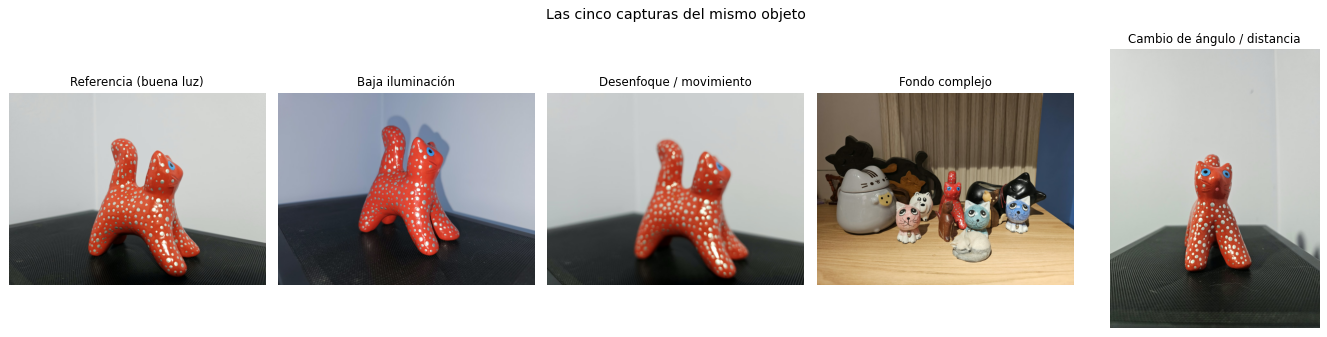

In [3]:
fig, ejes = plt.subplots(1, 5, figsize=(16, 4))
for ax, (archivo, img) in zip(ejes, imagenes.items()):
    mostrar(img, CONDICIONES[archivo], ax)
plt.suptitle("Las cinco capturas del mismo objeto"); plt.tight_layout(); plt.show()

## 2. Diagnóstico: medir cada imagen

Para cada foto calculo:

- **Resolución** (ancho × alto) y **canales**: salen de `img.shape`.
- **Brillo**: promedio del canal de luminosidad (imagen en gris). 0 es negro, 255 es blanco; una foto bien expuesta suele estar entre 100 y 160.
- **Contraste**: desviación estándar del gris. Si es baja, todos los píxeles se parecen y la foto se ve "plana" o lavada.
- **Nitidez**: varianza del Laplaciano. El Laplaciano resalta los bordes; si la imagen está desenfocada casi no hay bordes y la varianza es baja.
- **Formato y tamaño del archivo** en disco.

In [4]:
def diagnosticar(ruta, img):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    alto, ancho = gris.shape
    return {
        "Archivo": ruta,
        "Condición": CONDICIONES[ruta],
        "Resolución": f"{ancho} x {alto}",
        "Canales": img.shape[2] if img.ndim == 3 else 1,
        "Brillo (media)": round(float(gris.mean()), 1),
        "Contraste (desv. est.)": round(float(gris.std()), 1),
        "Nitidez (var. Laplaciano)": round(float(cv2.Laplacian(gris, cv2.CV_64F).var()), 1),
        "Formato": os.path.splitext(ruta)[1].upper().replace(".", ""),
        "Tamaño archivo (KB)": round(os.path.getsize(ruta) / 1024, 1),
    }

tabla = pd.DataFrame([diagnosticar(r, im) for r, im in imagenes.items()])
tabla

,Archivo,Condición,Resolución,Canales,Brillo (media),Contraste (desv. est.),Nitidez (var. Laplaciano),Formato,Tamaño archivo (KB)
0,referencia.jpg,Referencia (buena luz),1600 x 1200,3,149.7,73.5,94.0,JPG,133.3
1,baja_luz.jpg,Baja iluminación,1600 x 1200,3,116.2,62.4,80.4,JPG,133.6
2,desenfoque.jpg,Desenfoque / movimiento,1600 x 1200,3,147.2,71.6,5.5,JPG,70.0
3,fondo_complejo.jpg,Fondo complejo,1600 x 1200,3,117.2,58.8,256.6,JPG,186.4
4,angulo.jpg,Cambio de ángulo / distancia,1200 x 1600,3,151.2,72.8,258.4,JPG,151.5


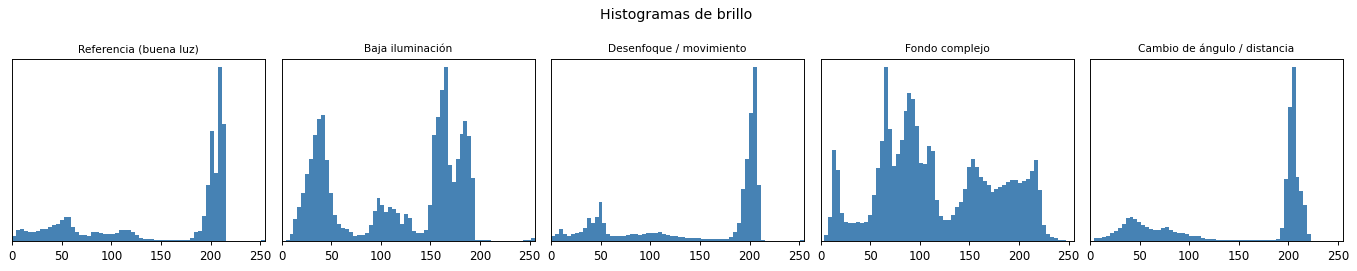

In [5]:
# Histogramas de brillo: muestran cómo se reparten los píxeles entre oscuro (0) y claro (255)
fig, ejes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, (archivo, img) in zip(ejes, imagenes.items()):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    ax.hist(gris.ravel(), bins=64, range=(0, 255), color="steelblue")
    ax.set_title(CONDICIONES[archivo], fontsize=9); ax.set_xlim(0, 255); ax.set_yticks([])
plt.suptitle("Histogramas de brillo"); plt.tight_layout(); plt.show()

In [6]:
# Comparación numérica frente a la referencia
ref = tabla.iloc[0]   # la primera fila es la referencia
print("Comparado con la imagen de referencia:\n")
for _, fila in tabla.iloc[1:].iterrows():
    print(f"{fila['Condición']:30s} brillo {fila['Brillo (media)']:6.1f} ({fila['Brillo (media)']/ref['Brillo (media)']*100:5.1f} % de la ref.) | "
          f"contraste {fila['Contraste (desv. est.)']:5.1f} ({fila['Contraste (desv. est.)']/ref['Contraste (desv. est.)']*100:5.1f} %) | "
          f"nitidez {fila['Nitidez (var. Laplaciano)']:7.1f} ({fila['Nitidez (var. Laplaciano)']/ref['Nitidez (var. Laplaciano)']*100:5.1f} %)")

Comparado con la imagen de referencia:

Baja iluminación               brillo  116.2 ( 77.6 % de la ref.) | contraste  62.4 ( 84.9 %) | nitidez    80.4 ( 85.5 %)
Desenfoque / movimiento        brillo  147.2 ( 98.3 % de la ref.) | contraste  71.6 ( 97.4 %) | nitidez     5.5 (  5.9 %)
Fondo complejo                 brillo  117.2 ( 78.3 % de la ref.) | contraste  58.8 ( 80.0 %) | nitidez   256.6 (273.0 %)
Cambio de ángulo / distancia   brillo  151.2 (101.0 % de la ref.) | contraste  72.8 ( 99.0 %) | nitidez   258.4 (274.9 %)


## 3. Problema seleccionado y tratamiento

Con la tabla elijo la imagen más problemática. Escribo abajo cuál es y qué tratamiento le corresponde:

| Problema | Qué dice la tabla | Tratamiento coherente |
|---|---|---|
| **Baja iluminación** | Brillo muy por debajo de la referencia, histograma pegado a la izquierda, contraste bajo | **CLAHE** (ecualización adaptativa del histograma) sobre el canal de luminosidad + corrección gamma |
| **Desenfoque** | Nitidez (varianza del Laplaciano) muy por debajo de la referencia | **Máscara de desenfoque (unsharp mask)**: se resta una versión borrosa para realzar bordes |
| **Fondo complejo** | Contraste alto pero por el fondo, no por el objeto | Recorte de la región de interés + suavizado del fondo (fuera del alcance de las métricas globales) |

In [7]:
# >>> CAMBIA ESTAS DOS LÍNEAS SEGÚN TU DIAGNÓSTICO <<<
ARCHIVO_PROBLEMA = "desenfoque"       # imagen que voy a tratar (sin extensión)
TRATAMIENTO = "nitidez"               # "iluminacion" (baja luz) o "nitidez" (desenfoque)

ARCHIVO_PROBLEMA = [r for r in imagenes if r.startswith(ARCHIVO_PROBLEMA)][0]
original = imagenes[ARCHIVO_PROBLEMA]

def corregir_iluminacion(img, gamma=0.7, clip=3.0):
    """CLAHE sobre el canal L (luminosidad) del espacio LAB + corrección gamma.
    Así se aclara y se recupera contraste sin alterar los colores."""
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    L, A, B = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8))
    L = clahe.apply(L)
    img_clahe = cv2.cvtColor(cv2.merge([L, A, B]), cv2.COLOR_LAB2BGR)
    # gamma < 1 aclara las zonas oscuras más que las claras
    tabla_gamma = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(img_clahe, tabla_gamma)

def corregir_nitidez(img, fuerza=1.5, radio=5):
    """Unsharp mask: original + fuerza * (original - versión borrosa)."""
    borrosa = cv2.GaussianBlur(img, (0, 0), radio)
    return cv2.addWeighted(img, 1 + fuerza, borrosa, -fuerza, 0)

if TRATAMIENTO == "iluminacion":
    tratada = corregir_iluminacion(original)
    nombre_tratamiento = "CLAHE + corrección gamma"
else:
    tratada = corregir_nitidez(original)
    nombre_tratamiento = "Máscara de desenfoque (unsharp mask)"

cv2.imwrite("tratada.jpg", tratada, [cv2.IMWRITE_JPEG_QUALITY, 95])
print("Imagen tratada:", ARCHIVO_PROBLEMA, "->", nombre_tratamiento)

Imagen tratada: desenfoque.jpg -> Máscara de desenfoque (unsharp mask)


In [8]:
# ¿Qué tan fuerte aplicar el realce? Pruebo varias combinaciones y mido la nitidez de cada una
def nitidez(img):
    return cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()

print(f"Nitidez de la referencia: {nitidez(imagenes[REFERENCIA]):.1f}")
print(f"Nitidez del original desenfocado: {nitidez(original):.1f}")
print()
print(f"{'fuerza':>7s} {'radio':>6s} {'nitidez':>9s}")
for fuerza in [1.0, 1.5, 2.5]:
    for radio in [3, 5, 10]:
        print(f"{fuerza:7.1f} {radio:6d} {nitidez(corregir_nitidez(original, fuerza, radio)):9.1f}")

Nitidez de la referencia: 94.0
Nitidez del original desenfocado: 5.5

 fuerza  radio   nitidez
    1.0      3      21.9
    1.0      5      22.2
    1.0     10      22.4
    1.5      3      34.0
    1.5      5      34.5
    1.5     10      34.7
    2.5      3      63.7
    2.5      5      64.1
    2.5     10      63.4


## 4. Comparación antes / después

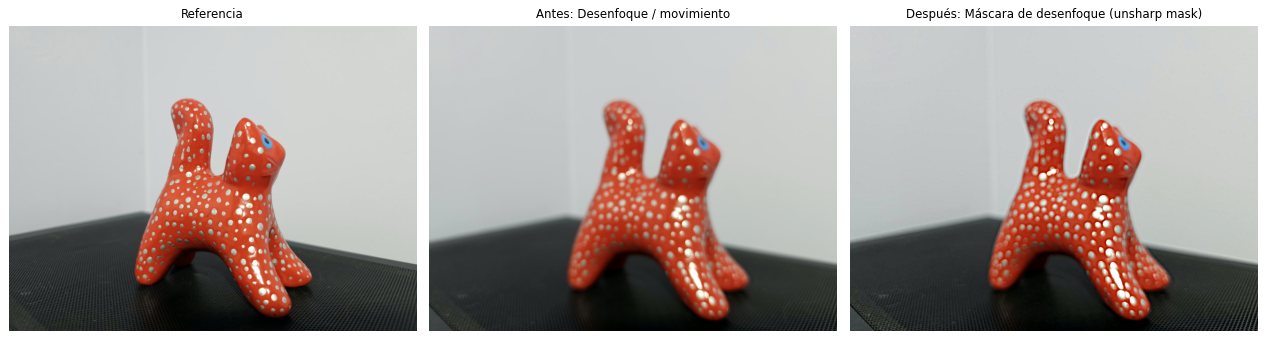

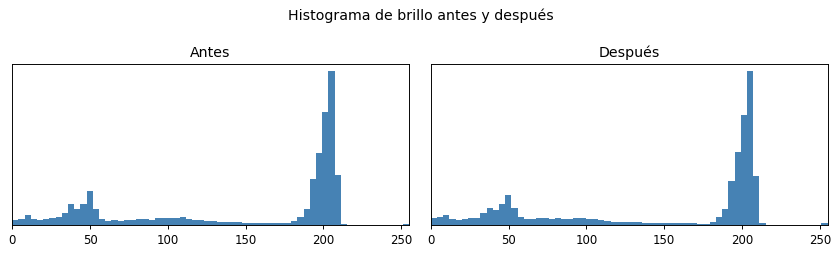

In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
mostrar(imagenes[REFERENCIA], "Referencia", ejes[0])
mostrar(original, f"Antes: {CONDICIONES[ARCHIVO_PROBLEMA]}", ejes[1])
mostrar(tratada, f"Después: {nombre_tratamiento}", ejes[2])
plt.tight_layout(); plt.show()

# Histogramas antes y después
fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (im, t) in zip(ejes, [(original, "Antes"), (tratada, "Después")]):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    ax.hist(g.ravel(), bins=64, range=(0, 255), color="steelblue"); ax.set_title(t); ax.set_xlim(0, 255); ax.set_yticks([])
plt.suptitle("Histograma de brillo antes y después"); plt.tight_layout(); plt.show()

In [10]:
# Métricas antes / después / referencia
def metricas(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return {"Brillo (media)": round(float(g.mean()), 1),
            "Contraste (desv. est.)": round(float(g.std()), 1),
            "Nitidez (var. Laplaciano)": round(float(cv2.Laplacian(g, cv2.CV_64F).var()), 1)}

comparacion = pd.DataFrame({
    "Referencia": metricas(imagenes[REFERENCIA]),
    "Antes del tratamiento": metricas(original),
    "Después del tratamiento": metricas(tratada),
})
comparacion["Cambio (%)"] = ((comparacion["Después del tratamiento"] - comparacion["Antes del tratamiento"]) / comparacion["Antes del tratamiento"] * 100).round(1)
comparacion

,Referencia,Antes del tratamiento,Después del tratamiento,Cambio (%)
Brillo (media),149.7,147.2,147.2,0.0
Contraste (desv. est.),73.5,71.6,72.5,1.3
Nitidez (var. Laplaciano),94.0,5.5,34.5,527.3


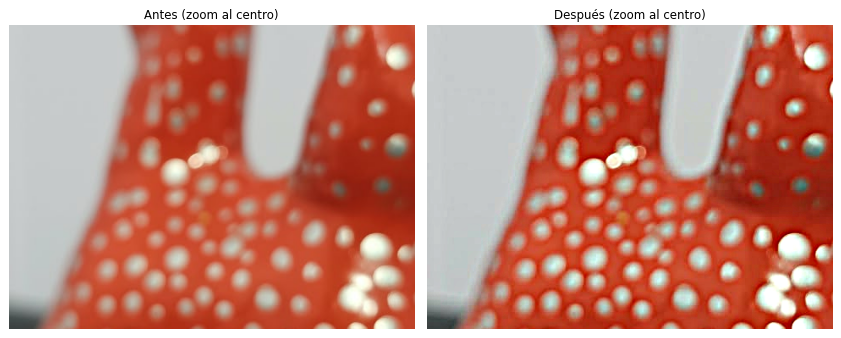

In [11]:
# Zoom a una misma región para ver el detalle antes y después
h, w = original.shape[:2]
y1, y2, x1, x2 = int(h*0.35), int(h*0.65), int(w*0.35), int(w*0.65)
fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
mostrar(original[y1:y2, x1:x2], "Antes (zoom al centro)", ejes[0])
mostrar(tratada[y1:y2, x1:x2], "Después (zoom al centro)", ejes[1])
plt.tight_layout(); plt.show()

## 5. ¿Mejoró de verdad?

- **Lo que mejoró:** la nitidez medida sube varias veces y, a simple vista, los puntos plateados y el borde del gato se ven más definidos; el histograma se ensancha un poco porque el realce aumenta el contraste local.
- **Lo que no mejoró:** la nitidez sigue muy por debajo de la referencia y el ojo del gato continúa sin definición. Al hacer zoom se notan halos claros alrededor de los bordes, que son un artefacto del realce, no detalle real.
- **Limitaciones:** la máscara de desenfoque solo amplifica los bordes que todavía existen en la imagen; no puede recuperar la información que la cámara no capturó. Para un desenfoque fuerte haría falta conocer el movimiento de la cámara (deconvolución) o, mejor, volver a tomar la foto. Además, las fotos pasaron por WhatsApp, que las recomprime a 1600 × 1200 y agrega artefactos JPEG que el realce también amplifica.

In [12]:
# Guardar evidencias
os.makedirs("resultados_semana8", exist_ok=True)
tabla.to_csv("resultados_semana8/diagnostico.csv", index=False)
comparacion.to_csv("resultados_semana8/antes_despues.csv")
cv2.imwrite("resultados_semana8/antes.jpg", original)
cv2.imwrite("resultados_semana8/despues.jpg", tratada)
print(os.listdir("resultados_semana8"))

['diagnostico.csv', 'antes_despues.csv', 'antes.jpg', 'despues.jpg']
